# Baseline: Logistic Regression + TF-IDF

**Goal:** predict whether a certificate program meets the Workforce Pell value-added earnings standard, using the program's numeric data (Scorecard, IPEDS, PSEO, BLS/O*NET, ETPL) **plus the text describing its field and related jobs**.

**Target:** `vae_positive_local`
- 1 = locally adjusted 1-year earnings are above 150% of the federal poverty line ($23,475)
- 0 = at or below, so value-added earnings are zero or negative and the program can't qualify

**Why this model is the baseline:**
- **Logistic regression** is the simplest classifier that still gives probabilities. Each coefficient shows how
  a feature pushes the prediction up or down, so it's explainable without extra tools.
- **TF-IDF** turns text into numbers the model can use. It counts how often each word appears in a row's text,
  and gives less weight to words that appear everywhere (like "and" or "workers").

## Decisions made in this notebook

| # | Decision | Choice | Why |
|---|---|---|---|
| 1 | Target | `vae_positive_local` | Closest public version of the Workforce Pell earnings test; 7,024 labeled programs |
| 2 | Text used for TF-IDF | `CIPDESC` (field name) + `xw_top_occupations` (related job titles) | The only real descriptive text in the merged file. School names are excluded (the model would memorize schools) |
| 3 | Features | The 121 features in `data/processed/model/model_features.csv` (Feature_Engineering notebook): numeric features scaled, low-cardinality categoricals one-hot encoded. `cipcode` is left out because the TF-IDF text already identifies the field | Same feature set as the other models; leakage, IDs and fairness-only columns were removed upstream |
| 4 | Student demographics (`UGDS_WHITE`, etc.) | **Excluded** (switch: `INCLUDE_DEMOGRAPHICS`) | A funding score shouldn't rate programs by who they serve; Step 9 measures the accuracy cost |
| 5 | Train / test / CV | Train on `split == "train"` with the shared `cv_fold` column (5 folds grouped by school); report the final model once on the held-out `split == "test"` | Every model uses the same folds and test set, and no school appears in both training and testing |
| 6 | Class imbalance (78% / 22%) | `class_weight="balanced"` | Without it the model leans toward always predicting "meets" |
| 7 | Regularization strength `C` | Tuned from [0.01, 0.1, 1, 10] | Keeps the model from overfitting the ~2,000 text features |
| 8 | Main metrics | F1 and ROC-AUC (plus accuracy, precision, recall) | Accuracy alone is misleading: always guessing "meets" scores 78% |

---------
## Step 0 — Setup and load

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import PredefinedSplit, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import joblib

DATA_DIR = Path("../../../data/processed/model")      # output of notebooks/modeling/Feature_Engineering.ipynb
OUTPUT_DIR = "../../../models/lr_tfidf"
RANDOM_STATE = 42
INCLUDE_DEMOGRAPHICS = False    # set True to include student race/ethnicity shares

dictionary = pd.read_csv(DATA_DIR / "feature_dictionary.csv")
CATEGORICAL = dictionary.loc[dictionary["type"] == "categorical", "feature"].tolist()
df = pd.read_csv(DATA_DIR / "model_features.csv", low_memory=False, dtype={c: str for c in CATEGORICAL})
print("Shape:", df.shape)

Shape: (26678, 151)


## Step 1 — Features from the feature dictionary
The agreed column drops (Tom's review doc), leakage removal, categorical clean-up and engineered features are all done
in `Feature_Engineering.ipynb`. Here we just read the feature list and column types from `feature_dictionary.csv`.

In [2]:
FEATURES = dictionary["feature"].tolist()
print("Features:", len(FEATURES), "| categorical:", CATEGORICAL)
print(dictionary["score_part"].value_counts().to_string())

Features: 121 | categorical: ['bea_region', 'cipcode', 'cip_series', 'y1_earnings_natl_benchmark_level', 'iclevel', 'control', 'highest_offering', 'calendar_system', 'price_reporting', 'locale', 'locale_group', 'preddeg']
score_part
institution             48
cost / aid              23
eligibility / length    15
demand                  11
earnings                10
completion               8
geography                3
placement                3


## Step 2 — Target, training rows and held-out test set
Only programs with earnings data have a label (decision 1). The shared `split` column puts 80% of labeled
programs in `train` (used for tuning and cross-validation) and 20% in `test` (used once, at the end). Unlabeled
programs (`score_only`) are scored at the end.

In [3]:
TARGET = "vae_positive_local"
labeled = df[df["split"] == "train"].copy()      # training rows ("labeled" keeps the name used below)
test = df[df["split"] == "test"].copy()
y = labeled[TARGET].astype(int)
y_test = test[TARGET].astype(int)
groups = labeled["unitid"]

print("Training programs:", len(labeled), "| schools:", groups.nunique())
print("Held-out test programs:", len(test), "| schools:", test["unitid"].nunique())
print("Unlabeled programs (scored at the end):", (df["split"] == "score_only").sum())
print(y.value_counts().rename({1: "1 = meets", 0: "0 = does not meet"}).to_string())
print(f"\nAlways guessing 'meets' = {y.mean():.1%} accuracy -> the bar to beat")

Training programs: 5619 | schools: 1642
Held-out test programs: 1405 | schools: 437
Unlabeled programs (scored at the end): 19654
vae_positive_local
1 = meets            4402
0 = does not meet    1217

Always guessing 'meets' = 78.3% accuracy -> the bar to beat


**Notes:**

- **Target = `vae_positive_local`:** 1 if a program's locally adjusted 1-year earnings are above $23,475 (150% of the poverty line), 0 if not.
- **7,024 of 26,678 programs (26%) have a label.** The shared split puts **5,619 in training** (1,642 schools) and **1,405 in the held-out test set** (437 different schools). The 19,654 unlabeled programs get a score from the finished model.
- Folds and the test set are grouped by school (`unitid`), so the model is never evaluated on a school it trained on.
- **Class balance in training: 4,402 meet (78%) vs. 1,217 don't (22%).** This is imbalanced, so:
  - A "model" that always guesses "meets" would already be **78.3% accurate**. Any real model has to beat that.
  - That's why **F1 and ROC-AUC** are our main metrics, not accuracy.
  - We use `class_weight="balanced"` so the model doesn't ignore the smaller "doesn't meet" group.
- **Caveat:** labeled programs aren't a random sample. For-profit schools make up 39% of labeled programs but only 16% of all programs, so results may not carry over evenly to programs without earnings data.

## Step 3 — Build the text field for TF-IDF

Decision 2: combine the **field of study name** and the **related occupation titles** into one text column.
- `CIPDESC`: e.g. "Welding Technology/Welder."
- `xw_top_occupations`: e.g. "Welders, Cutters, Solderers, and Brazers; ..." (from the CIP–SOC crosswalk + BLS)

Both describe the field, not the individual program, so programs in the same field share the same text.
TF-IDF lets the model learn which kinds of fields and jobs (e.g. "nursing", "technicians", "assistants") go with
meeting the earnings standard.

In [4]:
def build_text(frame):
    text = (frame["cipdesc"].fillna("") + " | " + frame["xw_top_occupations"].fillna(""))
    return (text.str.lower()
                .str.replace(r"[^a-z\s]", " ", regex=True)   # keep letters only
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())

df["program_text"] = build_text(df)
labeled["program_text"] = df.loc[labeled.index, "program_text"]
test["program_text"] = df.loc[test.index, "program_text"]

print("Rows with empty text:", (df["program_text"] == "").sum())
print("Unique text values:", df["program_text"].nunique())
print("\nExample:\n", labeled["program_text"].iloc[0][:300])

Rows with empty text: 0
Unique text values: 360

Example:
 dental support services and allied professions dental assistants dental hygienists health specialties teachers postsecondary


## Step 4 — Numeric and categorical features
- **Numeric:** every non-categorical feature in the dictionary. Leakage, IDs and fairness-only columns (including
  race/ethnicity shares) were already removed in feature engineering.
- **Categorical:** the low-cardinality categories (`control`, `iclevel`, `locale`, `bea_region`, `cip_series`, ...),
  one-hot encoded inside the pipeline. `cipcode` is left out: the TF-IDF text already identifies the field.
- **Demographics:** race/ethnicity shares are fairness-only columns in the file; set `INCLUDE_DEMOGRAPHICS = True`
  to add them (decision 4).

In [5]:
CAT_FEATURES = [c for c in CATEGORICAL if c != "cipcode"]
NUMERIC_FEATURES = [c for c in FEATURES if c not in CATEGORICAL]
DEMOGRAPHICS = ["ugds_white", "ugds_black", "ugds_hisp", "ugds_asian", "ugds_aian", "ugds_nhpi", "ugds_2mor"]
if INCLUDE_DEMOGRAPHICS:
    NUMERIC_FEATURES += DEMOGRAPHICS

print("Numeric features:", len(NUMERIC_FEATURES))
print("Categorical (one-hot):", CAT_FEATURES)
print("Demographics included:", INCLUDE_DEMOGRAPHICS)

Numeric features: 109
Categorical (one-hot): ['bea_region', 'cip_series', 'y1_earnings_natl_benchmark_level', 'iclevel', 'control', 'highest_offering', 'calendar_system', 'price_reporting', 'locale', 'locale_group', 'preddeg']
Demographics included: False


## Step 5 — Build the pipeline
Everything is inside one scikit-learn `Pipeline`, so in each cross-validation fold the TF-IDF vocabulary,
the median fill values, the one-hot categories and the scaling are learned **from the training rows only**.
Fitting them on all rows first would leak information from the test rows.

| Piece | Setting | Why |
|---|---|---|
| `TfidfVectorizer` | words + 2-word phrases, `min_df=5`, English stop words, `sublinear_tf`, max 2,000 terms | Phrases like "medical assistants" carry meaning; `min_df=5` drops very rare words; stop words remove "and", "of" |
| `SimpleImputer(median)` + `StandardScaler` | numeric | Logistic regression can't handle blanks; scaling makes coefficients comparable |
| `OneHotEncoder` | categorical, `drop="first"` | Linear models need numbers; dropping one level per category avoids perfect collinearity |
| `LogisticRegression` | `class_weight="balanced"`, `max_iter=5000` | Decision 6; enough iterations to converge |

In [6]:
def make_lr_pipeline(use_text=True, use_numeric=True, C=1.0, numeric=None):
    parts = []
    if use_text:
        parts.append(("text", TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english",
                                               sublinear_tf=True, max_features=2000), "program_text"))
    if use_numeric:
        parts.append(("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric or NUMERIC_FEATURES))
        parts.append(("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                           OneHotEncoder(drop="first", handle_unknown="ignore")), CAT_FEATURES))
    pre = ColumnTransformer(parts, remainder="drop")
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=5000, solver="lbfgs")
    return Pipeline([("prep", pre), ("clf", clf)])

INPUT_COLS = ["program_text"] + NUMERIC_FEATURES + CAT_FEATURES
X = labeled[INPUT_COLS]
X_test = test[INPUT_COLS]
cv = PredefinedSplit(labeled["cv_fold"])      # shared 5 folds, grouped by school
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
print("Pipeline ready.")

Pipeline ready.


## Step 6 — Tune regularization (`C`)
Smaller `C` = stronger regularization (simpler model, smaller coefficients). We pick the `C` with the best
cross-validated ROC-AUC (decision 7).

*Note:* for a baseline we tune and evaluate with the same folds, which can make scores slightly optimistic.
Nested cross-validation would fix that, but the difference is usually small.

In [7]:
grid = GridSearchCV(make_lr_pipeline(), param_grid={"clf__C": [0.01, 0.1, 1, 10]},
                    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X, y, groups=groups)

tuning = pd.DataFrame(grid.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]]
tuning.columns = ["C", "ROC-AUC (mean)", "ROC-AUC (std)"]
print(tuning.round(4).to_string(index=False))
BEST_C = grid.best_params_["clf__C"]
print("\nBest C:", BEST_C)

    C  ROC-AUC (mean)  ROC-AUC (std)
 0.01          0.9390         0.0110
 0.10          0.9424         0.0085
 1.00          0.9422         0.0073
10.00          0.9403         0.0060

Best C: 0.1


**Notes:**

- Tested 4 regularization strengths (`C` = 0.01, 0.1, 1, 10) on the shared 5 school-grouped folds.
- **Best: C = 0.1 (ROC-AUC 0.942).** All four scored between 0.939 and 0.942, so the model isn't sensitive to this choice.
- Fold-to-fold variation (std ≈ 0.007–0.011) is larger than the differences between `C` values, so any `C` from 0.1 to 1 would be a reasonable choice.
- Caveat: tuning and scoring used the same folds, which can make cross-validated scores slightly optimistic. The held-out test set (Step 12) gives the unbiased number.

## Step 7 — Does TF-IDF help? Compare text-only, numeric-only and combined
Same folds and same `C` for all three, plus the "always guess meets" reference.
If text + numeric doesn't beat numeric-only, the text isn't adding information.

In [8]:
variants = {
    "Always 'meets' (dummy)": DummyClassifier(strategy="most_frequent"),
    "LR - text only (TF-IDF)": make_lr_pipeline(use_text=True, use_numeric=False, C=BEST_C),
    "LR - numeric only": make_lr_pipeline(use_text=False, use_numeric=True, C=BEST_C),
    "LR - text + numeric": make_lr_pipeline(use_text=True, use_numeric=True, C=BEST_C),
}

results = {}

for name, model in variants.items():
    s = cross_validate(model, X, y, cv=cv, groups=groups, scoring=scoring)
    results[name] = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in scoring}

results_df = pd.DataFrame(results).T
results_df

,accuracy,precision,recall,f1,roc_auc
Always 'meets' (dummy),0.783 ± 0.000,0.783 ± 0.000,1.000 ± 0.000,0.879 ± 0.000,0.500 ± 0.000
LR - text only (TF-IDF),0.871 ± 0.012,0.916 ± 0.011,0.920 ± 0.016,0.918 ± 0.008,0.900 ± 0.016
LR - numeric only,0.886 ± 0.006,0.959 ± 0.008,0.893 ± 0.013,0.925 ± 0.004,0.942 ± 0.008
LR - text + numeric,0.888 ± 0.007,0.959 ± 0.008,0.896 ± 0.012,0.926 ± 0.005,0.942 ± 0.009


**Notes:**
- Compared 4 versions using the same 5 school-grouped folds and the same `C` (0.1):

| Model | F1 | ROC-AUC | vs. previous |
|---|---|---|---|
| Always guess "meets" (dummy) | 0.879 | 0.500 | — (bar to beat) |
| Text only (TF-IDF) | 0.918 | 0.900 | Beats the dummy using **only** field + job titles |
| Numeric + categorical only | 0.925 | 0.942 | +0.042 ROC-AUC over text only |
| **Text + numeric + categorical** | **0.926** | **0.942** | +0.001 F1, same ROC-AUC |

- **Every model beats the dummy.** The dummy's F1 (0.879) looks high only because it labels everything "meets." Its ROC-AUC of 0.500 shows it can't tell programs apart.
- **Text alone is strong (0.900 ROC-AUC):** the field of study and related jobs predict earnings well.
- **Text adds almost nothing on top of the engineered features.** The feature-engineered data already describes the field (`cip_series`, field-level earnings benchmarks, `expected_vae_field`, `entry_occ_wage`), so the TF-IDF terms overlap with it.
- **Precision is high (0.959) and recall is lower (0.896).** When the model says "meets," it's right 96% of the time, but it misses about 10% of programs that do meet the standard.

## Step 8 — Errors: confusion matrix (out-of-fold)
Each program is predicted by a model that never saw its school.
- **False positive:** predicted "meets" but doesn't. The costlier mistake for a funding tool.
- **False negative:** predicted "doesn't meet" but does. A good program gets overlooked.

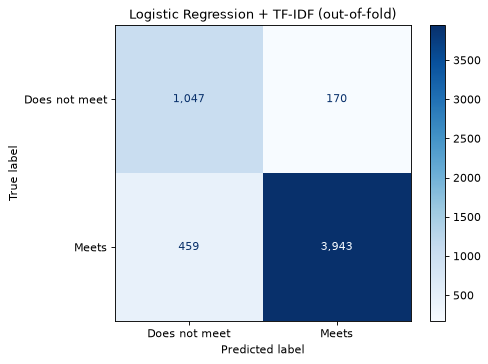

False positives (predicted meets, doesn't): 170
False negatives (predicted doesn't, meets): 459


In [9]:
final_model = make_lr_pipeline(C=BEST_C)
oof_prob = cross_val_predict(final_model, X, y, cv=cv, groups=groups, method="predict_proba")[:, 1]
oof_pred = (oof_prob >= 0.5).astype(int)

cm = confusion_matrix(y, oof_pred)
ConfusionMatrixDisplay(cm, display_labels=["Does not meet", "Meets"]).plot(cmap="Blues", values_format=",")
plt.title("Logistic Regression + TF-IDF (out-of-fold)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"False positives (predicted meets, doesn't): {fp:,}")
print(f"False negatives (predicted doesn't, meets): {fn:,}")

**Notes:**
Out-of-fold predictions for the 5,619 training programs (each predicted by a model that never saw its school):

- **Correct overall: 4,990 of 5,619 (88.8%)**, vs. 78.3% for always guessing "meets."
- **False positives: 170.** Programs the model says meet the standard but don't. Only **14%** of failing programs slip through, and when the model says "meets," it's right **96%** of the time (precision).
- **False negatives: 459.** Good programs the model rates as not meeting the standard. The model catches **90%** of programs that meet it (recall) and misses 10%.
- **When the model says "does not meet," it's right only 70% of the time** (1,047 of 1,506). So a "does not meet" prediction should prompt a closer look, not an automatic rejection.
- **Why it leans this way:** `class_weight="balanced"` makes the model more careful about calling a program "meets," which lowers false positives at the cost of more false negatives.
- **Possible adjustment:** the cutoff is 0.5. Raising it would cut false positives further (stricter); lowering it would catch more good programs.

## Step 9 — Effect of the demographics decision
Runs the combined model once with student race/ethnicity shares and once without, so the team can see the
accuracy cost of decision 4.

In [10]:
demo_in = DEMOGRAPHICS
X_demo = labeled[INPUT_COLS + [c for c in demo_in if c not in INPUT_COLS]].copy()

no_demo = [c for c in NUMERIC_FEATURES if c not in demo_in]
with_demo = no_demo + demo_in
comp = {}
for name, cols in [("Without demographics", no_demo), ("With demographics", with_demo)]:
    s = cross_validate(make_lr_pipeline(C=BEST_C, numeric=cols), X_demo, y, cv=cv, groups=groups, scoring=["f1", "roc_auc"])
    comp[name] = {"F1": round(s["test_f1"].mean(), 3), "ROC-AUC": round(s["test_roc_auc"].mean(), 3)}
pd.DataFrame(comp).T

,F1,ROC-AUC
Without demographics,0.926,0.942
With demographics,0.925,0.943


**Notes:**
- Ran the same model twice: once **without** student race/ethnicity shares and once **with** them.
- **Including demographics changes nothing meaningful:** F1 0.926 vs. 0.925 and ROC-AUC 0.942 vs. 0.943, well within the fold-to-fold variation (±0.009).
- **Decision: exclude them** (`INCLUDE_DEMOGRAPHICS = False`). Using a school's racial makeup to score programs could rate programs lower because of **who they serve** rather than how well they serve them, and leaving them out costs no accuracy.
- **They stay in the dataset as fairness-only columns,** together with HBCU / HSI / tribal flags, so we can still test whether scores differ across student populations.
- **Caveat:** removing these columns doesn't guarantee fairness. Related features like Pell share can still act as stand-ins, which is why the fairness check (Step 11) is still needed.

## Step 10 — What the model learned (coefficients)
Fit on all labeled programs and read the coefficients. This is how logistic regression explains itself.
- **Positive** = pushes toward "meets the standard"
- **Negative** = pushes toward "doesn't meet"
- Numeric features are scaled, so their sizes are comparable with each other.

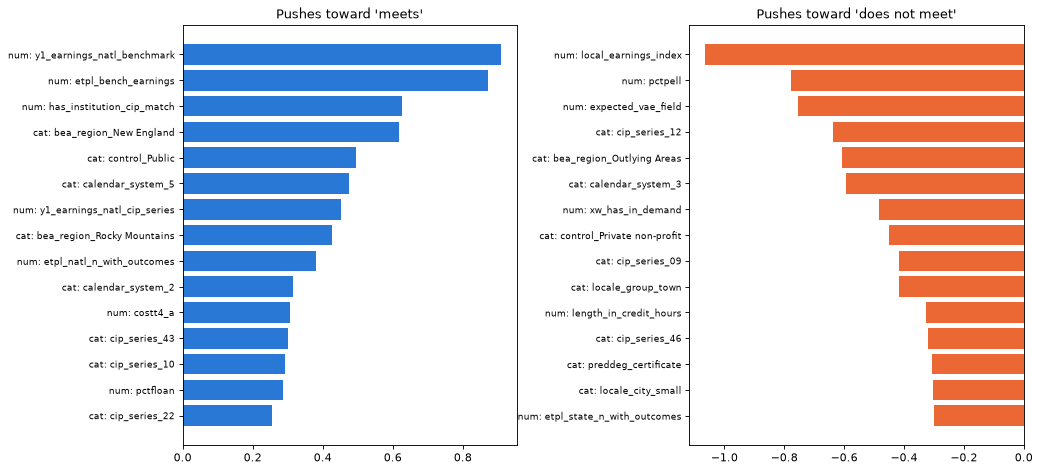

Top text terms (meets):    ['social workers', 'air', 'conditioning', 'refrigeration', 'heating air', 'air conditioning', 'heating', 'social', 'veterinary', 'health services']
Top text terms (doesn't):  ['personal', 'service', 'trades general', 'line', 'grooming', 'grooming services', 'supervisors personal', 'manicurists pedicurists', 'hairdressers', 'pedicurists']


In [11]:
final_model.fit(X, y)
prep = final_model.named_steps["prep"]
coefs = final_model.named_steps["clf"].coef_[0]

names = [n.replace("__", ": ", 1) for n in prep.get_feature_names_out()]
coef_s = pd.Series(coefs, index=names)

top_pos = coef_s.sort_values(ascending=False).head(15)
top_neg = coef_s.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(top_pos.index[::-1], top_pos.values[::-1], color="#2a78d6")
axes[0].set_title("Pushes toward 'meets'")
axes[1].barh(top_neg.index[::-1], top_neg.values[::-1], color="#eb6834")
axes[1].set_title("Pushes toward 'does not meet'")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Top text terms (meets):   ", [t.replace("text: ", "") for t in coef_s.filter(like="text:").sort_values(ascending=False).head(10).index])
print("Top text terms (doesn't): ", [t.replace("text: ", "") for t in coef_s.filter(like="text:").sort_values().head(10).index])

**Notes:**
The chart shows the 15 strongest coefficients in each direction for the final model (fit on the 5,619 training programs). Numeric features are scaled and categoricals are one-hot, so bar lengths can be compared.

**Signals that make sense:**
- **`y1_earnings_natl_benchmark` and `etpl_bench_earnings` (+):** programs in fields that pay well (PSEO national and ETPL state/national field earnings) are more likely to meet the standard.
- **Text toward "meets":** *heating / air conditioning / refrigeration, social workers, veterinary, health services*.
- **Text and `cip_series_12` toward "does not meet":** *personal, hairstylists / cosmetologists, grooming, manicurists / pedicurists*. Personal-care fields earn less, which matches the earlier analysis.
- **`pctpell` (−):** schools serving more low-income students have lower earnings outcomes. This reflects students' circumstances as much as program quality, so watch it in the fairness check.

**Signals that come from how the label is built (not discoveries):**
- **`local_earnings_index` (strongest, −):** the label divides earnings by this index, so a higher index automatically lowers adjusted earnings.

**Signals to read with caution:**
- **`expected_vae_field` (−):** this is `etpl_bench_earnings ÷ local_earnings_index − $23,475`, so it overlaps with the two features above. With all three in a linear model, the coefficients split the effect in opposite directions. **Read them as a group**, or use SHAP from the tree models.
- **`has_institution_cip_match` (+):** whether the school + program appears in PSEO. It mostly reflects which programs PSEO covers (and where the label came from), not program quality.
- **Region and calendar-system categories** (e.g. New England +, Outlying Areas −) pick up regional differences that the local index doesn't fully remove.

**Takeaway:** the model relies on sensible signals (field earnings, healthcare/HVAC vs. personal-care fields), but overlapping features distort individual coefficients. Explain individual predictions with SHAP rather than these raw coefficients.

## Step 11 — Fairness check by school type (out-of-fold)
Does the model work equally well for public, non-profit and for-profit schools?

In [12]:
rows = []
for grp, idx in labeled.groupby("control").groups.items():
    pos = labeled.index.get_indexer(idx)
    yt, yp, pp = y.loc[idx], oof_pred[pos], oof_prob[pos]
    rows.append({"control": grp, "programs": len(idx), "actual pass rate": yt.mean(), "predicted pass rate": yp.mean(),
                 "precision": precision_score(yt, yp, zero_division=0), "recall": recall_score(yt, yp, zero_division=0),
                 "F1": f1_score(yt, yp, zero_division=0),
                 "ROC-AUC": roc_auc_score(yt, pp) if yt.nunique() > 1 else np.nan})
pd.DataFrame(rows).round(3)

,control,programs,actual pass rate,predicted pass rate,precision,recall,F1,ROC-AUC
0,Private for-profit,2225,0.574,0.470,0.917,0.750,0.825,0.918
1,Private non-profit,226,0.743,0.704,0.912,0.863,0.887,0.853
2,Public,3168,0.933,0.918,0.976,0.960,0.968,0.912


**Notes:**
Out-of-fold results by school type (each program predicted by a model that never saw its school):

| School type | Programs | Actual pass | Predicted pass | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|---|
| Private for-profit | 2,225 | 0.574 | 0.470 | 0.917 | 0.750 | 0.825 | 0.918 |
| Private non-profit | 226 | 0.743 | 0.704 | 0.912 | 0.863 | 0.887 | 0.853 |
| Public | 3,168 | 0.933 | 0.918 | 0.976 | 0.960 | 0.968 | 0.912 |

- **Precision is high for every school type (91–98%).** When the model says a program meets the standard, it's usually right no matter who runs it.
- **The model under-predicts passing for for-profit schools by about 10 points** (47% predicted vs. 57% actual). For public schools the gap is about 1.5 points.
- **Recall is lowest for for-profit schools (75.0%):** about **1 in 4 for-profit programs that meet the standard get labeled "does not meet."** For non-profits it's about 1 in 7; for public schools, 1 in 25.
- **Non-profit results are the least reliable:** only 226 training programs and the lowest ROC-AUC (0.853).
- **Each group's ROC-AUC (0.85–0.92) is lower than the overall 0.942.** Part of the model's skill comes from telling school *types* apart; ranking programs **within** a type is harder.

**Why it matters:** if the Opportunity Score is used for funding decisions, strong for-profit programs are more likely to be overlooked. Report recall by school type alongside the overall metrics, and compare with the tree models, which captured for-profit programs better.

## Step 12 — Held-out test set
The final model (fit on the training rows) is scored once on the `test` programs, which were never used for tuning or
cross-validation and come from schools not in the training set. This is the honest estimate to report.

In [13]:
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
test_results = pd.Series({"accuracy": accuracy_score(y_test, test_pred), "precision": precision_score(y_test, test_pred),
                          "recall": recall_score(y_test, test_pred), "f1": f1_score(y_test, test_pred),
                          "roc_auc": roc_auc_score(y_test, test_prob)}, name="held-out test")
print(f"Test programs: {len(y_test):,} | pass rate {y_test.mean():.1%}")
test_results.round(3).to_frame()

Test programs: 1,405 | pass rate 78.4%


,held-out test
accuracy,0.893
precision,0.974
recall,0.887
f1,0.929
roc_auc,0.957


**Notes:**
- **Held-out test (1,405 programs from 437 schools never used in training): accuracy 0.893, precision 0.974, recall 0.887, F1 0.929, ROC-AUC 0.957.**
- The test scores are as good as or slightly better than cross-validation (F1 0.926, ROC-AUC 0.942), so the model generalizes to new schools and the CV numbers weren't optimistic.
- Use these test numbers when comparing models in the final presentation; every model notebook uses the same test set.


## Step 13 — Score every program and save
The final model (fit on the training programs) gives every program, labeled or not, a probability of meeting
the earnings standard. This becomes the earnings part of the Opportunity Score.
Training programs also get their out-of-fold probability (`p_vae_oof`), the honest score to use for evaluation.

In [14]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["p_vae_lr"] = final_model.predict_proba(df[INPUT_COLS])[:, 1]
df.loc[labeled.index, "p_vae_oof"] = oof_prob

out = df[["unitid", "instnm", "state", "cipcode", "cipdesc", "control", "split",
          "vae_positive_local", "earnings_1yr_local_adj", "p_vae_lr", "p_vae_oof"]]
out.to_csv(f"{OUTPUT_DIR}/lr_tfidf_predictions.csv", index=False)
joblib.dump(final_model, f"{OUTPUT_DIR}/lr_tfidf_model.joblib")
results_df.to_csv(f"{OUTPUT_DIR}/lr_tfidf_cv_results.csv")
test_results.to_frame().T.to_csv(f"{OUTPUT_DIR}/lr_tfidf_test_results.csv")

print("Saved predictions:", out.shape)
print("Saved model, CV and test results to:", OUTPUT_DIR)

Saved predictions: (26678, 11)
Saved model, CV and test results to: ../../../models/lr_tfidf


## Summary

*Rerun on the feature-engineered data (`data/processed/model/model_features.csv`) with the shared train/test split and CV folds.*

- **Best `C`:** 0.1 (CV ROC-AUC 0.942). All values tested (0.01–10) scored between 0.939 and 0.942, so the model is stable.
- **Cross-validation (text + numeric + categorical):** **F1 0.926 / ROC-AUC 0.942** (accuracy 88.8%, precision 0.959, recall 0.896). Clearly beats "always guess meets" (accuracy 78.3%, ROC-AUC 0.500).
- **Held-out test set:** **F1 0.929 / ROC-AUC 0.957** (accuracy 89.3%, precision 0.974, recall 0.887). The number to report.
- **Did TF-IDF help?** Barely (+0.001 F1, same ROC-AUC). The engineered features already describe the field, so the text overlaps with them. Text alone still reaches ROC-AUC 0.900.
- **Demographics decision cost:** none (ROC-AUC 0.942 without vs. 0.943 with). Excluded from the model, kept for fairness checks.
- **Top signals (coefficients):**
  - Toward *meets:* high field earnings (`y1_earnings_natl_benchmark`, `etpl_bench_earnings`), and HVAC, social-work, veterinary and health-services fields.
  - Toward *does not meet:* higher Pell share and personal-care fields (cosmetology, grooming, manicuring).
  - `local_earnings_index` is strongly negative **because of how the label is built**. `expected_vae_field` overlaps with the benchmark and index features, so read those together or use SHAP.
- **Fairness:** precision is high for every school type (0.91–0.98), but the model **under-predicts passing for for-profit schools by about 10 points** and misses **about 1 in 4 for-profit programs** that meet the standard (recall 0.750 vs. 0.960 for public).
- **Errors (out-of-fold):** 170 false positives (14% of failing programs slip through) and 459 false negatives (10% of good programs missed). A "does not meet" prediction is right only 70% of the time, so it should prompt review, not rejection.
- **Limitations:**
  - Text describes the **field**, not the individual program (360 unique values).
  - The label is an **estimate** of the official Workforce Pell test: all-completer earnings instead of Pell-recipient earnings, and an ETPL earnings index standing in for BEA price parities.
  - Trained only on programs with earnings data, which over-represent for-profit schools (39% of labeled vs. 16% overall).
- **Next steps:** compare against the tree models on the same test set, check calibration by school type, and extend the fairness check to HBCU / HSI / tribal / rural schools.

## Workforce Pell Requirements: What This Model Evaluates

**Short answer:** this baseline evaluates **one** Workforce Pell requirement, the **value-added earnings test**, and only its first part: whether a program's locally adjusted earnings are above 150% of the federal poverty line ($23,475). The other requirements are either used as model inputs, saved for the Opportunity Score, or can't be measured with public data.

### Requirement coverage

| Workforce Pell requirement | Evaluated? | How | Why / why not |
|---|---|---|---|
| **Value-added earnings:** earnings − 150% poverty line ≥ tuition and fees | ⚠️ **Partly (the model's target)** | `vae_positive_local` = 1 if locally adjusted 1-yr earnings > $23,475 | Earnings data exists for 7,024 programs (26%). The **cost comparison** (`passes_vae_local`) has data for only 2,986 programs, mostly for-profit, so it's a validation check instead of the target |
| **70% completion** within 150% of normal time | ❌ Not as a target (used as a feature) | `C150_L4`, `etpl_bench_completion` | ETPL has program-level completion for 12,367 programs, but only **2,103** link to our main dataset (ETPL has no school ID; matched by name + state). Scorecard completion is school-wide |
| **70% job placement** within 180 days | ❌ Not as a target (used as a feature) | `etpl_bench_employment_q2` | ETPL reports 2nd-quarter employment (≈180 days) for 10,351 programs, but only **1,888** link to our main dataset |
| **Program length:** 150–599 clock hours, 8 to under 15 weeks | ❌ No | — | ETPL has length for 23,307 programs and IPEDS for 3,644, but only **2,657** ETPL lengths link to our main dataset |
| **Aligned with high-skill, high-wage or in-demand jobs** | ❌ Not as a target (used as features) | BLS wages, job counts, `xw_has_in_demand` | Each state defines its own in-demand list. Our BLS data is national only |
| **Program offered for at least 1 year** | ❌ No | — | Not in any public dataset we have |
| **At least 75% of instruction delivered by the school** | ❌ No | — | Not in any public dataset we have |
| **State approval** (governor / state workforce board) | ❌ No | — | A government decision, not a measurement |
| **School participates in federal student aid** | ✅ Yes (built in) | All programs come from College Scorecard | Scorecard only includes federal-aid schools |
| **Program is a certificate** (not a degree) | ✅ Yes (built in) | Dataset is undergraduate certificates only | Filtered when the dataset was built |

### Why the model focuses on earnings
1. **It's the only requirement with enough program-level data to train on** (7,024 labeled programs vs. 1,888 for placement).
2. **It's a hard requirement.** Programs with zero or negative value-added earnings can't qualify, so it's a meaningful first filter.
3. **It can be adjusted for local conditions,** as Workforce Pell requires, using the ETPL-based local earnings index.

### How our version differs from the official test
| Official rule | Our version | Reason |
|---|---|---|
| Earnings of **Pell-recipient** completers | Earnings of **all** completers (Scorecard, PSEO as backup) | Pell-only earnings aren't published |
| Adjusted with **BEA regional price parities** | Adjusted with an **ETPL state earnings index** | BEA data not available to the team |
| Measured over **several years**, minimum number of completers | **One** snapshot | Only one year of data |
| Earnings compared to **published tuition and fees** | Cost comparison only where IPEDS cost exists (2,986 programs) | Most programs lack program-level cost data |

### Where the other requirements come in
- **Opportunity Score (planned):** combines this model's prediction (earnings, 40%) with **completion** (20%), **placement** (20%) and **job demand** (20%).
- **Eligibility flags (planned):** program length and short-term certificate status, used as dashboard filters.
- **Validation:** ETPL's 70% completion / 70% placement data (1,768 programs) tests whether high-scoring programs also do well on the other standards.

> **Bottom line:** the model estimates whether a program meets the **earnings component** of Workforce Pell eligibility. It does **not** determine eligibility. Several requirements depend on state decisions or data that isn't publicly available.